# EA2 - Regresión lineal

**Dataset:** [`mayacheruty/Horse-Race-Prediction-EDA`](https://huggingface.co/datasets/mayacheruty/Horse-Race-Prediction-EDA) (Hugging Face)

Este notebook se ejecuta de principio a fin sin cargar archivos a mano: los datos se descargan de Hugging Face en el momento de la ejecución.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "src" / "clases_po").exists():
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT / "src"))

from clases_po import HFDatasetLoader, PreprocesamientoCarreras, InterpretacionModelos, RegresionLineal, AlmacenResultados

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

/home/runner/work/ML_2026_IUD/ML_2026_IUD/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Construcción automática del DataFrame

### Origen de los datos

| Ítem | Valor |
|---|---|
| Identificador | `mayacheruty/Horse-Race-Prediction-EDA` |
| Enlace | https://huggingface.co/datasets/mayacheruty/Horse-Race-Prediction-EDA |
| Configuración | `default` |
| Split | `train` (único split disponible) |
| Archivo fuente | `data/horse_racing_cleaned.csv` |
| Licencia | MIT |
| Contenido | Una fila por caballo en una carrera: edad, peso, cuota de mercado, ratings, entrenador, jinete, linaje y resultado |

### Columnas relevantes para este trabajo

| Columna | Rol | Descripción |
|---|---|---|
| `RPR` | **Objetivo de regresión** | Racing Post Rating: rating numérico del desempeño del caballo en la carrera |
| `res_win` | **Objetivo de clasificación** | 1 si el caballo ganó la carrera, 0 si no. Ya es binaria, no se construye a partir de una variable numérica |
| `OR` | Predictora (regresión) | Official Rating: rating oficial asignado antes de la carrera |
| `age` | Predictora | Edad del caballo en años |
| `weight` | Predictora | Peso que carga el caballo (kg) |
| `decimalPrice` | Predictora | Probabilidad implícita de la cuota de mercado (0 a 1) |
| `runners` | Predictora | Número de participantes en la carrera |
| `rid` | Agrupación | Identificador de la carrera. Se usa para dividir entrenamiento y prueba, no como predictora |
| `position`, `positionL`, `dist`, `margin`, `res_place` | Excluidas | Describen el resultado de la carrera: revelarían la respuesta |
| `weightSt`, `weightLb` | Excluidas | Mismo dato que `weight` en otras unidades (correlación 0,999) |
| `isFav` | Excluida | Se deriva de `decimalPrice` (es 1 para el caballo con mayor valor de la carrera) |
| `TR` | Excluida | 37 % de nulos |
| `saddle` | Excluida | Número de cajón, con 0 usado como marcador de faltante y sin aporte medible |
| `horseName`, `trainerName`, `jockeyName`, `father`, `mother`, `gfather` | Excluidas | Texto con miles de valores distintos |

In [2]:
hfdataset = HFDatasetLoader(
    dataset_name="mayacheruty/Horse-Race-Prediction-EDA",
    split="train",
    filename="datos/horse-race-prediction-eda.csv"
)
df = hfdataset.load()
print(hfdataset.info())

Generating train split:   0%|          | 0/171849 [00:00<?, ? examples/s]

Generating train split:  23%|██▎       | 40000/171849 [00:00<00:00, 287852.86 examples/s]

Generating train split:  47%|████▋     | 80000/171849 [00:00<00:00, 310083.88 examples/s]

Generating train split:  70%|██████▉   | 120000/171849 [00:00<00:00, 318032.38 examples/s]

Generating train split:  93%|█████████▎| 160000/171849 [00:00<00:00, 316493.70 examples/s]

Generating train split: 100%|██████████| 171849/171849 [00:00<00:00, 311485.43 examples/s]

{'dataset': 'mayacheruty/Horse-Race-Prediction-EDA', 'config': None, 'split': 'train', 'filas': 171849, 'columnas': 24}


### Estructura y contenido del DataFrame

In [3]:
print(f"Filas: {len(df)}")
print(f"Columnas: {len(df.columns)}")
print()
df.info()

Filas: 171849
Columnas: 24

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 171849 entries, 0 to 171848
Data columns (total 24 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   rid           171849 non-null  int64  
 1   horseName     171849 non-null  object 
 2   age           171849 non-null  float64
 3   saddle        171849 non-null  float64
 4   decimalPrice  171849 non-null  float64
 5   isFav         171849 non-null  int64  
 6   trainerName   171849 non-null  object 
 7   jockeyName    171849 non-null  object 
 8   position      171849 non-null  int64  
 9   positionL     146630 non-null  object 
 10  dist          129373 non-null  object 
 11  weightSt      171849 non-null  int64  
 12  weightLb      171849 non-null  int64  
 13  RPR           171849 non-null  float64
 14  TR            108282 non-null  float64
 15  OR            171849 non-null  float64
 16  father        171849 non-null  object 
 17  mother        171849

In [4]:
df.head(10)

,rid,horseName,age,saddle,decimalPrice,isFav,trainerName,jockeyName,position,positionL,dist,weightSt,weightLb,RPR,TR,OR,father,mother,gfather,runners,margin,weight,res_win,res_place
0,11499,Picken,4.0,6.0,0.312500,0,J Size,Joao Moreira,1,None,None,8,13,69.0,NaN,54.0,Duporth,Baby Boom,Redoute's Choice,13,1.217349,56,1.0,1
1,11499,Noble De Love,6.0,7.0,0.333333,1,F C Lor,Zac Purton,2,nk,None,8,12,67.0,NaN,53.0,Commands,Terrenora,Encosta De Lago,13,1.217349,56,0.0,1
2,11499,Fresh Power,5.0,3.0,0.200000,0,Y S Tsui,Silvestre De Sousa,3,2.5,2.75,9,1,63.0,NaN,56.0,Makfi,Bannisters,Redoute's Choice,13,1.217349,57,0.0,1
3,11499,Happy Hour,4.0,5.0,0.017544,0,C H Yip,Umberto Rispoli,4,1.25,4.0,8,13,58.0,NaN,54.0,Mastercraftsman,Jolly Genie,Generous,13,1.217349,56,0.0,0
4,11499,Super Fun,5.0,8.0,0.090909,0,L Ho,Matthew Poon,5,1,5.0,8,9,54.0,NaN,53.0,Dandy Man,Dame Hester,Diktat,13,1.217349,54,0.0,0
5,11499,Blizzing Away,3.0,11.0,0.004587,0,P F Yiu,K C Leung,6,.5,5.5,8,8,49.0,NaN,49.0,All Too Hard,Quackquack,Starcraft,13,1.217349,54,0.0,0
6,11499,Multigogo,5.0,1.0,0.029412,0,A S Cruz,Alberto Sanna,7,nk,5.75,9,5,59.0,NaN,60.0,Drumbeats,Lights Off,Way Of Light,13,1.217349,59,0.0,0
7,11499,Virtus Star,3.0,12.0,0.027027,0,D J Hall,Chad Schofield,8,shd,6.0,8,7,47.0,NaN,48.0,Sebring,Princess Natural,Danehill Dancer,13,1.217349,53,0.0,0
8,11499,Monica,5.0,4.0,0.161290,0,John Moore,Douglas Whyte,9,1,7.0,9,0,51.0,NaN,55.0,Murtajill,Senorita De Lago,Encosta De Lago,13,1.217349,57,0.0,0
9,11499,Regency Gem,4.0,9.0,0.027778,0,W Y So,Alexis Badel,10,.75,7.75,8,11,46.0,NaN,52.0,Showcasing,The Myth,Cape Cross,13,1.217349,55,0.0,0


In [5]:
df.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
rid,171849.0,117721.129,44980.872,3.000,99508.000,129858.000,151567.000,172742.000
age,171849.0,4.826,2.160,2.000,3.000,4.000,6.000,16.000
saddle,171849.0,6.515,4.204,0.000,3.000,6.000,9.000,40.000
decimalPrice,171849.0,0.120,0.119,0.002,0.038,0.083,0.164,0.962
isFav,171849.0,0.107,0.309,0.000,0.000,0.000,0.000,1.000
position,171849.0,7.572,8.112,1.000,3.000,6.000,9.000,40.000
weightSt,171849.0,9.195,1.056,6.000,8.000,9.000,10.000,12.000
weightLb,171849.0,6.067,4.088,0.000,2.000,6.000,10.000,13.000
RPR,171849.0,74.055,27.177,1.000,57.000,74.055,91.000,181.000
TR,108282.0,48.638,27.272,1.000,28.000,46.000,65.000,177.000


### Definición de los dos problemas

- **Regresión:** predecir `RPR` (variable numérica casi continua) a partir de variables conocidas antes de la carrera: `OR`, `age`, `weight`, `decimalPrice` y `runners`.
- **Clasificación:** predecir `res_win` (ganó / no ganó). Solo el 10 % de los caballos gana, por lo que la exactitud sola engaña y se evaluará con precisión, recall, F1 y matriz de confusión.

Ninguna variable de resultado de la carrera (`position`, `positionL`, `dist`, `margin`, `res_place`) puede usarse como predictora en ninguno de los dos modelos.

## 2. Preprocesamiento

### 2.1 Estado Inicial

In [6]:
prep = PreprocesamientoCarreras(columna_grupo="rid", test_size=0.2, random_state=42)

print("Filas duplicadas:", int(df.duplicated().sum()))
print()
diagnostico_inicial = prep.diagnosticar(df)
display(diagnostico_inicial)

Filas duplicadas: 0



,tipo,nulos,pct_nulos,distintos
rid,int64,0,0.00,17233
horseName,object,0,0.00,41241
age,float64,0,0.00,15
saddle,float64,0,0.00,41
decimalPrice,float64,0,0.00,586
isFav,int64,0,0.00,2
trainerName,object,0,0.00,3991
jockeyName,object,0,0.00,2929
position,int64,0,0.00,31
positionL,object,25219,14.68,192


El README del dataset indica que los valores faltantes de `RPR` y `OR` se rellenaron con la media. Los ratings reales son números enteros, así que un valor con decimales delata una imputación. Se comprueba:

In [7]:
imputados = prep.detectar_imputados(df)
display(imputados)

,valores_imputados,pct_imputados,valores_decimales_distintos,valor_imputado
columna,,,,
OR,69860,40.65,1,81.516311
RPR,18651,10.85,1,74.054746


Cada rating tiene **un único valor decimal** repetido miles de veces: es la media usada para rellenar. El 40,65 % de `OR` y el 10,85 % de `RPR` no son mediciones reales. Mantenerlos crearía un pico artificial en la distribución y sesgaría los coeficientes de la regresión.

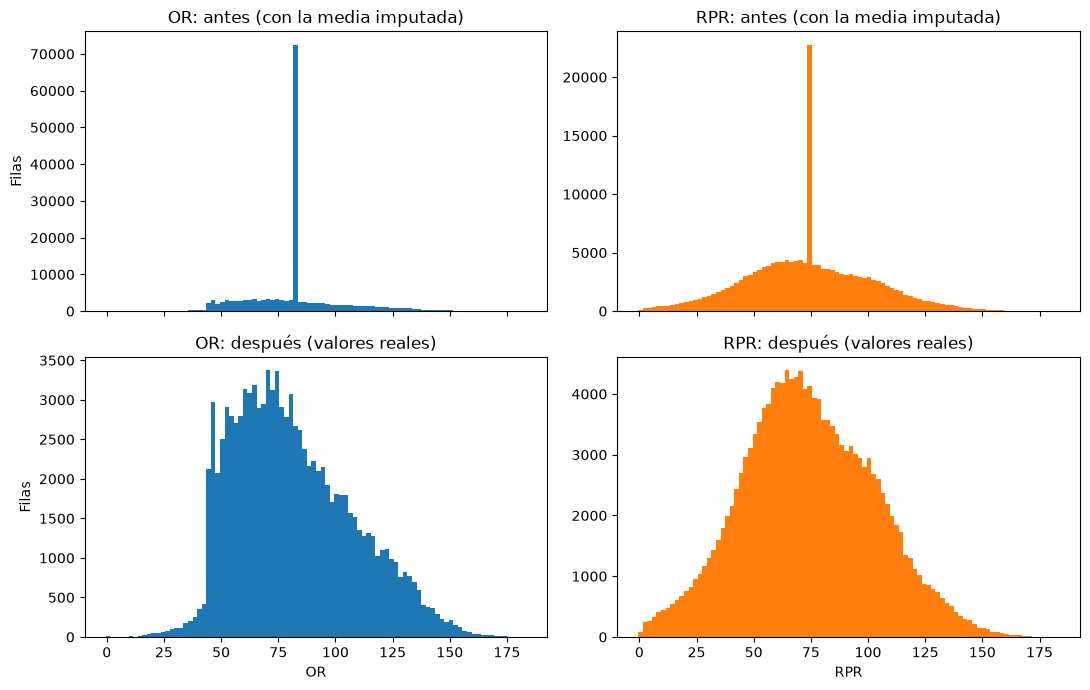

In [8]:
restaurado = PreprocesamientoCarreras().restaurar_nulos_imputados(df)

bordes = np.arange(-0.5, 184.5, 2)  # cada intervalo agrupa 2 enteros: evita efectos de redondeo
fig, ejes = plt.subplots(2, 2, figsize=(11, 7), sharex="col")
for columna, color, x in (("OR", "tab:blue", 0), ("RPR", "tab:orange", 1)):
    ejes[0, x].hist(df[columna], bins=bordes, color=color)
    ejes[0, x].set_title(f"{columna}: antes (con la media imputada)")
    ejes[1, x].hist(restaurado[columna].dropna(), bins=bordes, color=color)
    ejes[1, x].set_title(f"{columna}: después (valores reales)")
    ejes[1, x].set_xlabel(columna)
for eje in ejes[:, 0]:
    eje.set_ylabel("Filas")
plt.tight_layout()
plt.show()

### 2.2 Operaciones aplicadas

| # | Operación | Problema que resuelve | Efecto sobre los datos |
|---|---|---|---|
| 1 | Eliminar duplicados | Filas repetidas contarían dos veces | No hay duplicados: sin cambios |
| 2 | Devolver a `NaN` los ratings imputados | Valores que no son mediciones reales | `OR` y `RPR` recuperan sus faltantes verdaderos |
| 3 | Seleccionar columnas | Fuga de información, redundancia y texto de alta cardinalidad | De 24 columnas quedan 5 predictoras, el objetivo y `rid` |
| 4 | Descartar filas con nulos | La regresión no admite nulos y el objetivo no debe imputarse | Quedan solo filas con `OR` y `RPR` reales |
| 5 | División por carrera (80/20) | Caballos de una misma carrera comparten rasgos y contaminarían la prueba | Ninguna carrera aparece en ambos conjuntos |
| 6 | Escalado estandarizado | Variables en unidades distintas (puntos, kg, años) | Media 0 y desviación 1, ajustado solo con entrenamiento |

In [9]:
X, y, grupos = prep.preparar_regresion(
    df,
    objetivo="RPR",
    predictoras=["OR", "age", "weight", "decimalPrice", "runners"],
)
display(prep.resumen_operaciones())

[preparar_regresion] X=['OR', 'age', 'weight', 'decimalPrice', 'runners']; y='RPR'; 94740 filas de 171849; 11975 carreras.


,operacion,problema_que_resuelve,filas_antes,filas_despues,detalle
0,eliminar_duplicados,Filas repetidas que contarían dos veces en el ...,171849,171849,duplicados eliminados: 0
1,restaurar_nulos_imputados,Ratings imputados con la media por el autor de...,171849,171849,"valores devueltos a NaN: OR=69860, RPR=18651"
2,seleccionar_columnas,"Quitar identificadores, texto de alta cardinal...",171849,171849,7 de 24 columnas conservadas
3,descartar_filas_con_nulos,Un modelo lineal no admite nulos y el objetivo...,171849,94740,"nulos por columna: OR=69860, RPR=18651"


### 2.3 Comparación antes y después

In [10]:
def resumen(frame, nombre):
    return pd.Series(
        {
            "filas": len(frame),
            "columnas": frame.shape[1],
            "carreras": frame["rid"].nunique(),
            "nulos totales": int(frame.isna().sum().sum()),
            "OR media": round(frame["OR"].mean(), 2),
            "OR desv.": round(frame["OR"].std(), 2),
            "RPR media": round(frame["RPR"].mean(), 2),
            "RPR desv.": round(frame["RPR"].std(), 2),
        },
        name=nombre,
    )

limpio = pd.concat([X, y, grupos], axis=1)
comparacion = pd.concat(
    [resumen(df, "antes (original)"), resumen(limpio, "después (preparado)")], axis=1
)
display(comparacion)

,antes (original),después (preparado)
filas,171849.00,94740.00
columnas,24.00,7.00
carreras,17233.00,11975.00
nulos totales,131432.00,0.00
OR media,81.52,80.78
OR desv.,20.24,25.80
RPR media,74.05,73.04
RPR desv.,27.18,29.74


Se pierde el 45 % de las filas, pero las que quedan tienen ratings reales. La media de `OR` y `RPR` cambia porque ya no hay un 40 % y un 11 % de filas con la media impuesta.

### 2.4 División entrenamiento / prueba y escalado

El escalador se ajusta **solo con el entrenamiento** y luego se aplica a la prueba. Por eso las medias del conjunto de prueba quedan cerca de 0 pero no exactamente en 0.

In [11]:
X_train, X_test, y_train, y_test = prep.dividir_por_carrera(X, y, grupos)
display(pd.Series(prep.info_division, name="división").to_frame())

[dividir_por_carrera] entrenamiento=75979 filas; prueba=18761 filas; carreras compartidas=0.


,división
filas_entrenamiento,75979.0
filas_prueba,18761.0
carreras_entrenamiento,9580.0
carreras_prueba,2395.0
carreras_compartidas,0.0
test_size,0.2
random_state,42.0


In [12]:
X_train_esc, X_test_esc = prep.escalar(X_train, X_test)

evidencia = pd.concat(
    {
        "entrenamiento sin escalar (media)": X_train.mean(),
        "entrenamiento escalado (media)": X_train_esc.mean(),
        "entrenamiento escalado (desv.)": X_train_esc.std(),
        "prueba escalada (media)": X_test_esc.mean(),
        "prueba escalada (desv.)": X_test_esc.std(),
    },
    axis=1,
).round(3)
display(evidencia)

[escalar] StandardScaler ajustado con entrenamiento y aplicado a prueba.


,entrenamiento sin escalar (media),entrenamiento escalado (media),entrenamiento escalado (desv.),prueba escalada (media),prueba escalada (desv.)
OR,80.800,0.0,1.0,-0.005,0.994
age,5.291,0.0,1.0,-0.004,1.001
weight,60.694,-0.0,1.0,-0.008,0.994
decimalPrice,0.128,0.0,1.0,0.005,0.992
runners,11.197,-0.0,1.0,-0.037,0.962


### Conclusiones del preprocesamiento

- El dataset publicado ya venía "limpio", pero esa limpieza incluyó imputar con la media casi la mitad de los ratings. Se revirtió detectando los valores no enteros, lo que no depende de ninguna estadística calculada con datos de prueba.
- El costo es una reducción del 45 % de las filas. No se imputan `OR` ni `RPR` porque `RPR` es el objetivo y `OR` es la variable más influyente.
- La división por carrera evita que la evaluación sea optimista.
- **Limitación:** `RPR` es un rating posterior a la carrera, así que el modelo predice un rating de desempeño a partir de datos previos, no el resultado de la carrera.

## 3. Modelo de regresión lineal e interpretación

### 3.1 Qué se predice, con qué variables y por qué este algoritmo

- **Qué se predice:** el `RPR`, el rating numérico del desempeño de un caballo en una carrera.
- **Algoritmo:** regresión lineal múltiple por mínimos cuadrados ordinarios (`LinearRegression` de scikit-learn), usada a través de la clase `RegresionLineal` del repositorio.
- **Por qué es adecuado:** el objetivo es un número en una escala amplia, no una categoría; la relación entre el rating oficial y el `RPR` es aproximadamente lineal (ver correlaciones más abajo); y entrega coeficientes que se pueden leer directamente, algo que importa para explicar qué influye en el rating.

| Variable | Por qué se usa |
|---|---|
| `OR` | Rating oficial asignado antes de la carrera: es la medida previa más cercana al `RPR` |
| `decimalPrice` | El mercado resume en una probabilidad lo que se sabe del caballo, el jinete y el entrenador |
| `age` | La edad se asocia con el rendimiento (los caballos jóvenes rinden distinto de los veteranos) |
| `weight` | Peso que carga el caballo; en carreras con hándicap se ajusta según el nivel del caballo |
| `runners` | Tamaño del lote: en carreras con más participantes el rendimiento relativo cambia |

Todas son conocidas antes de que empiece la carrera. Se excluyen las variables de resultado para evitar fuga de información.

In [13]:
correlaciones = (
    pd.concat([X_train, y_train], axis=1)
    .corr()["RPR"]
    .drop("RPR")
    .round(3)
    .rename("correlación con RPR (solo entrenamiento)")
)
display(correlaciones.to_frame())

,correlación con RPR (solo entrenamiento)
OR,0.843
age,0.301
weight,0.608
decimalPrice,0.328
runners,-0.208


### 3.2 Configuración de entrenamiento y prueba

| Ítem | Valor |
|---|---|
| Algoritmo | `LinearRegression` (scikit-learn), mínimos cuadrados ordinarios |
| Hiperparámetros | Valores por defecto de scikit-learn; no se ajustó ninguno (se muestran abajo) |
| División | 80 % entrenamiento / 20 % prueba, por carrera (`GroupShuffleSplit`), `random_state=42` |
| Preprocesamiento | `StandardScaler` ajustado solo con el conjunto de entrenamiento |
| Persistencia | Modelo y preprocesador guardados en `entrenamiento/` con fecha y hora en el nombre |

In [14]:
regresion = RegresionLineal(
    feature_column=list(X_train_esc.columns),
    target_column="RPR",
    test_size=prep.test_size,
    random_state=prep.random_state,
)
datos_entrenamiento = regresion.entrenar(
    X_train=X_train_esc,
    y_train=y_train,
    directorio_entrenamiento="entrenamiento",
)
modelo = datos_entrenamiento["modelo"]
ruta_modelo = datos_entrenamiento["ruta_modelo"]
ruta_preprocesador = prep.guardar(
    ruta_modelo.with_name(ruta_modelo.name.replace("_modelo.pkl", "_preprocesador.pkl"))
)
print("Preprocesador guardado en:", ruta_preprocesador)
display(pd.Series(modelo.get_params(), name="valor").to_frame())

[entrenar] modelo ajustado con 75979 filas y 5 características.
[entrenar] modelo guardado en: entrenamiento/20261026_101731_843507_modelo.pkl
Preprocesador guardado en: entrenamiento/20261026_101731_843507_preprocesador.pkl


,valor
copy_X,True
fit_intercept,True
n_jobs,None
positive,False
tol,0.000001


### 3.3 Parámetros y resultados

El modelo se entrenó con las variables estandarizadas. El coeficiente estandarizado indica cuánto cambia el `RPR` por cada desviación estándar de la variable, lo que permite comparar la influencia de variables con unidades distintas. El coeficiente en unidades originales indica cuánto cambia por cada unidad (un punto de `OR`, un kilo, un año). Ambos describen el mismo modelo.

In [15]:
parametros = regresion.obtener_parametros(ruta_modelo)
tabla_coef, intercepto_original = InterpretacionModelos.coeficientes_regresion(
    modelo, list(X_train_esc.columns), prep.escalador
)
print(
    f"Intercepto con variables escaladas: {parametros['b']:.3f} | "
    f"en unidades originales: {intercepto_original:.3f}"
)
display(tabla_coef.round(4))

[obtener_parametros] modelo cargado desde entrenamiento/20261026_101731_843507_modelo.pkl; w=[24.4196014034664, 0.5319997585238666, -0.8179590110790574, 4.537668651130133, -0.6689027302443207]; b=73.0098.
Intercepto con variables escaladas: 73.010 | en unidades originales: -0.331


,coef_estandarizado,desv_variable,coef_unidad_original,peso_relativo_pct
OR,24.4196,25.8366,0.9452,78.8336
decimalPrice,4.5377,0.1131,40.1373,14.6489
weight,-0.8180,6.5822,-0.1243,2.6406
runners,-0.6689,3.9290,-0.1702,2.1594
age,0.5320,2.1932,0.2426,1.7175


In [16]:
metricas_test = regresion.evaluar(ruta_modelo, X_test_esc, y_test)
pred_test = regresion.predicciones
pred_train = modelo.predict(X_train_esc)
metricas_train = InterpretacionModelos.metricas_regresion(y_train, pred_train)
metricas_baseline = InterpretacionModelos.baseline_media(y_train, y_test)

tabla_metricas = pd.DataFrame(
    {
        "entrenamiento": metricas_train,
        "prueba": metricas_test,
        "baseline (siempre la media)": metricas_baseline,
    }
).round(3) + 0.0
display(tabla_metricas)

[predecir] modelo cargado desde entrenamiento/20261026_101731_843507_modelo.pkl; 18761 predicciones generadas.
[evaluar] modelo=entrenamiento/20261026_101731_843507_modelo.pkl; MAE=11.33; RMSE=15.11; R2=0.74.


,entrenamiento,prueba,baseline (siempre la media)
r2,0.735,0.740,0.000
mae,11.473,11.328,23.752
rmse,15.336,15.112,29.625


**Métricas elegidas.** El objetivo es numérico y no hay clases que balancear, por lo que se usan tres medidas complementarias:

- **R²:** proporción de la variación del `RPR` que explica el modelo. 1 sería perfecto y 0 equivale a predecir siempre la media.
- **MAE:** error absoluto medio, en puntos de `RPR`. Es la medida más fácil de leer.
- **RMSE:** como el MAE pero penaliza más los errores grandes. Si es mucho mayor que el MAE, hay errores extremos.

La columna *baseline* es el modelo más simple posible (predecir siempre la media del entrenamiento) y sirve para saber si el modelo aporta algo.

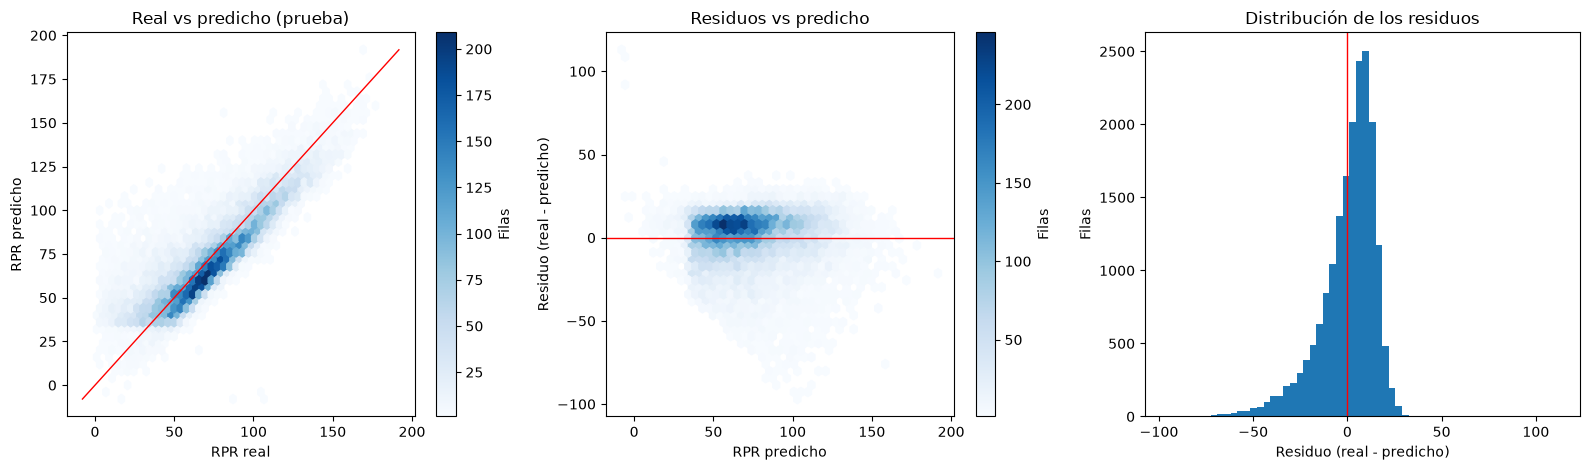

In [17]:
residuos = y_test.to_numpy() - pred_test
fig, ejes = plt.subplots(1, 3, figsize=(16, 4.8))

grafico = ejes[0].hexbin(y_test, pred_test, gridsize=45, cmap="Blues", mincnt=1)
limites = [min(y_test.min(), pred_test.min()), max(y_test.max(), pred_test.max())]
ejes[0].plot(limites, limites, color="red", linewidth=1)
ejes[0].set_xlabel("RPR real")
ejes[0].set_ylabel("RPR predicho")
ejes[0].set_title("Real vs predicho (prueba)")
fig.colorbar(grafico, ax=ejes[0], label="Filas")

grafico = ejes[1].hexbin(pred_test, residuos, gridsize=45, cmap="Blues", mincnt=1)
ejes[1].axhline(0, color="red", linewidth=1)
ejes[1].set_xlabel("RPR predicho")
ejes[1].set_ylabel("Residuo (real - predicho)")
ejes[1].set_title("Residuos vs predicho")
fig.colorbar(grafico, ax=ejes[1], label="Filas")

ejes[2].hist(residuos, bins=60, color="tab:blue")
ejes[2].axvline(0, color="red", linewidth=1)
ejes[2].set_xlabel("Residuo (real - predicho)")
ejes[2].set_ylabel("Filas")
ejes[2].set_title("Distribución de los residuos")

plt.tight_layout()
plt.show()

In [18]:
vif = InterpretacionModelos.factores_inflacion_varianza(X_train_esc)
diagnostico = InterpretacionModelos.diagnostico_residuos(y_test, pred_test, y_train)
variable_principal = tabla_coef.index[0]
r2_variable_principal = InterpretacionModelos.r2_variable_sola(
    X_train_esc, y_train, X_test_esc, y_test, variable_principal
)

display(vif.round(2).to_frame())
display(
    pd.Series(diagnostico["desv_por_cuartil"], name="desviación del residuo")
    .round(2)
    .rename_axis("cuartil de la predicción")
    .to_frame()
)
display(
    pd.Series({k: v for k, v in diagnostico.items() if k != "desv_por_cuartil"})
    .round(3)
    .to_frame("valor")
)
print(f"R² usando solo {variable_principal}: {r2_variable_principal:.3f}")

,VIF
OR,2.16
age,1.35
weight,2.41
decimalPrice,1.22
runners,1.16


,desviación del residuo
cuartil de la predicción,
Q1,13.33
Q2,13.72
Q3,15.97
Q4,17.09


,valor
objetivo_p10_entrenamiento,37.000
objetivo_p90_entrenamiento,114.000
residuo_medio_decil_bajo,-21.735
residuo_medio_decil_alto,9.337
media,0.239
desviacion,15.110
asimetria,-1.372
curtosis_exceso,3.401
pct_fuera_2_desviaciones,4.914
prediccion_min,-7.930


R² usando solo OR: 0.718


In [19]:
interpretacion = InterpretacionModelos.interpretar_regresion(
    objetivo="RPR",
    metricas_train=metricas_train,
    metricas_test=metricas_test,
    baseline=metricas_baseline,
    coeficientes=tabla_coef,
    vif=vif,
    residuos=diagnostico,
    correlaciones=correlaciones,
)
display(Markdown("### 3.4 Interpretación de los resultados\n\n" + "\n".join(f"- {linea}" for linea in interpretacion)))

### 3.4 Interpretación de los resultados

- Ajuste: el modelo explica el 74.0 % de la variación de RPR en carreras que no vio al entrenar (R² = 0.740, nivel alto). Un modelo que siempre predice la media obtiene R² = 0.000.
- Error: el MAE es 11.33 puntos de RPR, un 52 % menor que el del modelo de la media (23.75). El RMSE (15.11) es mayor que el MAE porque penaliza más los errores grandes.
- Generalización: R² de 0.735 en entrenamiento y 0.740 en prueba (diferencia -0.005); no se observa sobreajuste.
- Coeficientes: OR concentra el 79 % del peso relativo del modelo. Por cada punto adicional de OR, RPR cambia +0.945 puntos, con las demás variables constantes.
- Efecto de las demás variables: decimalPrice (+4.54 puntos por desviación estándar); weight (-0.82 puntos por desviación estándar); runners (-0.67 puntos por desviación estándar); age (+0.53 puntos por desviación estándar).
- Variables con efecto pequeño (menos de 1 punto por desviación estándar): weight, runners, age. Los signos describen asociación, no causalidad.
- Signo contrario: weight tiene correlación +0.61 con RPR pero coeficiente -0.82. Una vez descontado el efecto de las demás variables su aporte cambia de dirección; no debe leerse de forma aislada.
- Multicolinealidad: el VIF máximo es 2.41 (weight); es bajo, así que los coeficientes son estables.
- Residuos: media +0.24 (sin sesgo sistemático) y desviación 15.11.
- Los residuos tienen asimetría -1.37: hay casos con RPR real mucho menor que el predicho, que el modelo tiende a sobreestimar.
- Las colas son pesadas (curtosis en exceso 3.4): el 4.9 % de los residuos supera dos desviaciones, más de lo que daría una distribución normal.
- Tendencia hacia la media: en el 10 % de casos con RPR real más bajo (hasta 37) el residuo medio es -21.7, y en el 10 % más alto (desde 114) es +9.3. Un residuo negativo significa que el modelo sobreestima; uno positivo, que subestima.
- La dispersión del error crece con el valor predicho: de 13.3 (cuartil bajo) a 17.1 (cuartil alto). El modelo es menos preciso para los valores altos.

In [20]:
limitaciones = InterpretacionModelos.limitaciones_regresion(
    objetivo="RPR",
    filas_originales=len(df),
    filas_usadas=len(X),
    variable_principal=variable_principal,
    r2_variable_principal=r2_variable_principal,
    r2_modelo=metricas_test["r2"],
    residuos=diagnostico,
)
display(Markdown("### 3.5 Limitaciones\n\n" + "\n".join(f"- {linea}" for linea in limitaciones)))

### 3.5 Limitaciones

- RPR es un rating posterior a la carrera: el modelo estima el desempeño a partir de datos previos, pero no pronostica quién ganará una carrera.
- Se descartaron 77109 de 171849 filas (44.9 %) por tener ratings imputados con la media. Los resultados describen a los caballos con ratings registrados y pueden no generalizarse al resto.
- Casi todo el poder predictivo viene de OR: por sí sola alcanza R² = 0.718, y las demás variables aportan +0.022.
- El modelo supone una relación lineal y no captura interacciones. Los caballos de una misma carrera no son independientes; se evitó mezclarlos entre entrenamiento y prueba, pero no se calcularon intervalos de confianza ni valores p.
- La regresión lineal no está acotada: 7 predicciones quedaron fuera del rango observado en entrenamiento [1, 181].

In [21]:
resultados_regresion = {
    "dataset": hfdataset.info(),
    "preprocesamiento": prep.resumen_operaciones().to_dict("records"),
    "objetivo": "RPR",
    "predictoras": list(X_train_esc.columns),
    "algoritmo": "Regresión lineal múltiple (LinearRegression, mínimos cuadrados ordinarios)",
    "hiperparametros": modelo.get_params(),
    "configuracion": {
        **prep.info_division,
        "division": "por carrera (GroupShuffleSplit)",
        "escalado": "StandardScaler ajustado solo con entrenamiento",
    },
    "ruta_modelo": str(ruta_modelo),
    "intercepto_escalado": parametros["b"],
    "intercepto_original": intercepto_original,
    "coeficientes": tabla_coef.round(6).reset_index(names="variable").to_dict("records"),
    "metricas_entrenamiento": metricas_train,
    "metricas_prueba": metricas_test,
    "metricas_baseline": metricas_baseline,
    "vif": vif.round(4).to_dict(),
    "residuos": diagnostico,
    "variable_principal": variable_principal,
    "r2_variable_principal": r2_variable_principal,
    "filas_originales": len(df),
    "filas_usadas": len(X),
    "interpretacion": interpretacion,
    "limitaciones": limitaciones,
}
ruta_resultados = AlmacenResultados("resultados").guardar("regresion", resultados_regresion)
print("Resultados de la regresión guardados en:", ruta_resultados)
print("El notebook EA2_Clasificacion.ipynb los leerá para presentar el resultado conjunto.")

Resultados de la regresión guardados en: resultados/regresion.json
El notebook EA2_Clasificacion.ipynb los leerá para presentar el resultado conjunto.
